# E-Commerce Strategy Analysis
**Five Business Questions**

---

## Assumptions

| # | Assumption | Source | Impact if Wrong |
|---|---|---|---|
| A1 | Timestamps are in buyer's local timezone | Stated as fact in source|
| A2 | Buyers with null timezone default to Central | Engineering judgment | Minor — very few unresolved after imputation |
| A3 | Customer segment = `customer_group` field | Engineering judgment — brief says "segment", data has two segment columns | Changes Q2/Q4/Q5 groupings entirely |
| A4 | Referral discount = 10% off first order only | Dollar estimate scales linearly with rate |
| A5 | Black Friday eligibility based on customer's LOCAL timezone | Slightly more BF orders vs company tz |
| A6 | Delivered orders only count for revenue/profit | Business logic — Cancelled orders never fulfilled | Volume metrics count all statuses |
| A7 | Black Friday = 20% off all items that day (customer's local tz); not in raw price data | All BF revenue/profit already reflect the discount applied in pipeline |
| A8 | Customer shipping: <$50→$7.99, $50–$99.99→$4.99, ≥$100→free; company carrier cost $4.99/order | Net shipping P&L included in order_revenue and order_profit for every delivered order |

In [1]:
import sys
from pathlib import Path

project_root = Path().resolve().parent
sys.path.insert(0, str(project_root / 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from load     import load_sales, load_buyers, load_vendor_files
from clean    import clean_sales, clean_buyers, clean_vendors
from features import build_line_items, build_orders, estimate_referral_cost
from config   import SEGMENT_ORDER, REFERRAL_DISCOUNT_RATE

FIGURES_DIR = project_root / 'outputs' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='muted')

# run full pipeline
sales_raw   = load_sales()
buyers_raw  = load_buyers()
vendors_raw = load_vendor_files()

sales   = clean_sales(sales_raw)
buyers  = clean_buyers(buyers_raw)
vendors = clean_vendors(vendors_raw)

line_items = build_line_items(sales, vendors, buyers)
orders     = build_orders(line_items)

print(f'orders: {len(orders):,} rows')
print(f'revenue-eligible: {orders["is_revenue_eligible"].sum():,}')
print(f'BF orders: {orders["is_black_friday"].sum():,}')

  [sales] dropped 24,878 exact duplicate rows
  [sales] 394 rows flagged quantity_is_valid=False (null or > 50)
  [sales] dropped 322 rows with null buyer_id
  [buyers] dropped 2,634 rows with null buyer_id
  [buyers] dropped 2,366 exact duplicate rows
  [buyers] deduped to one row per buyer_id (0 additional rows removed)
  [buyers] null region after imputation:   0
  [buyers] null timezone after imputation: 0
  [vendors] 111 negative margin rows (loss-leaders) in: JDTOJ.csv, KWOXE.csv, NKDLI.csv, PQYYY.csv, SOPAJ.csv, TAAFL.csv, WQEPS.csv
orders: 244,121 rows
revenue-eligible: 235,237
BF orders: 2,639


---
## Q1 — Order Volume by Hour
*Does the current 24/7 staffing model make sense given actual order patterns?*

Total orders with time: 237,580
Overnight (12am-6am):  20,307 (8.5%)  [vs. 25% if evenly distributed]
Peak window (6am-12am): 91.5%


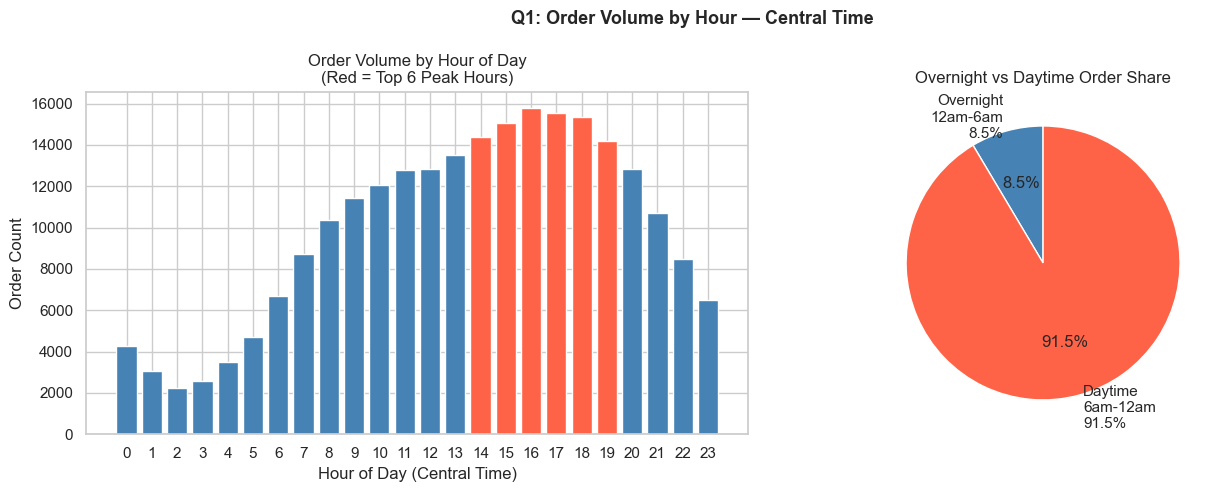

saved: q1_hourly_volume.png


In [2]:
timed = orders[orders['datetime_has_time'] & orders['order_hour_central'].notna()]

hourly = (
    timed.groupby('order_hour_central')
    .agg(order_count=('order_id', 'count'))
    .reset_index()
    .sort_values('order_hour_central')
)

overnight = hourly[hourly['order_hour_central'].between(0, 5)]['order_count'].sum()
total     = hourly['order_count'].sum()
overnight_pct = overnight / total * 100
peak_pct      = 100 - overnight_pct

peak_hours = hourly.nlargest(6, 'order_count')['order_hour_central'].values

uniform_overnight_pct = 6 / 24 * 100  # expected share if orders were evenly distributed

print(f'Total orders with time: {total:,}')
print(f'Overnight (12am-6am):  {overnight:,} ({overnight_pct:.1f}%)'
      f'  [vs. {uniform_overnight_pct:.0f}% if evenly distributed]')
print(f'Peak window (6am-12am): {peak_pct:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
colors = ['tomato' if h in peak_hours else 'steelblue'
          for h in hourly['order_hour_central']]
ax.bar(hourly['order_hour_central'], hourly['order_count'], color=colors)
ax.set_xlabel('Hour of Day (Central Time)')
ax.set_ylabel('Order Count')
ax.set_title('Order Volume by Hour of Day\n(Red = Top 6 Peak Hours)')
ax.set_xticks(range(0, 24))

ax2 = axes[1]
ax2.pie(
    [overnight_pct, peak_pct],
    labels=[f'Overnight\n12am-6am\n{overnight_pct:.1f}%',
            f'Daytime\n6am-12am\n{peak_pct:.1f}%'],
    colors=['steelblue', 'tomato'],
    autopct='%1.1f%%',
    startangle=90,
)
ax2.set_title('Overnight vs Daytime Order Share')

plt.suptitle('Q1: Order Volume by Hour — Central Time', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'q1_hourly_volume.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved: q1_hourly_volume.png')

### Q1 Findings
**Finding:** Order volume is heavily concentrated in daytime hours.
The overnight window (12am-6am Central) represents a small fraction of total orders.


---
## Q2 — Average Profit per Order by Quarter & Segment
* Which customer segments drive profitability, and is it consistent over time?*

Average profit per order ($):
order_quarter   2024-Q1  2024-Q2  2024-Q3  2024-Q4  2025-Q1  2025-Q2  2025-Q3  2025-Q4
customer_group                                                                        
VIP               64.61    60.20    62.90    68.75    63.72    64.10    64.19    65.72
Frequent          36.84    33.45    36.59    39.65    36.52    36.64    36.57    35.82
Regular           23.44    22.51    23.29    25.67    23.65    22.51    23.13    23.67
Occasional        19.51    20.26    20.14    23.04    19.89    21.20    20.97    20.07


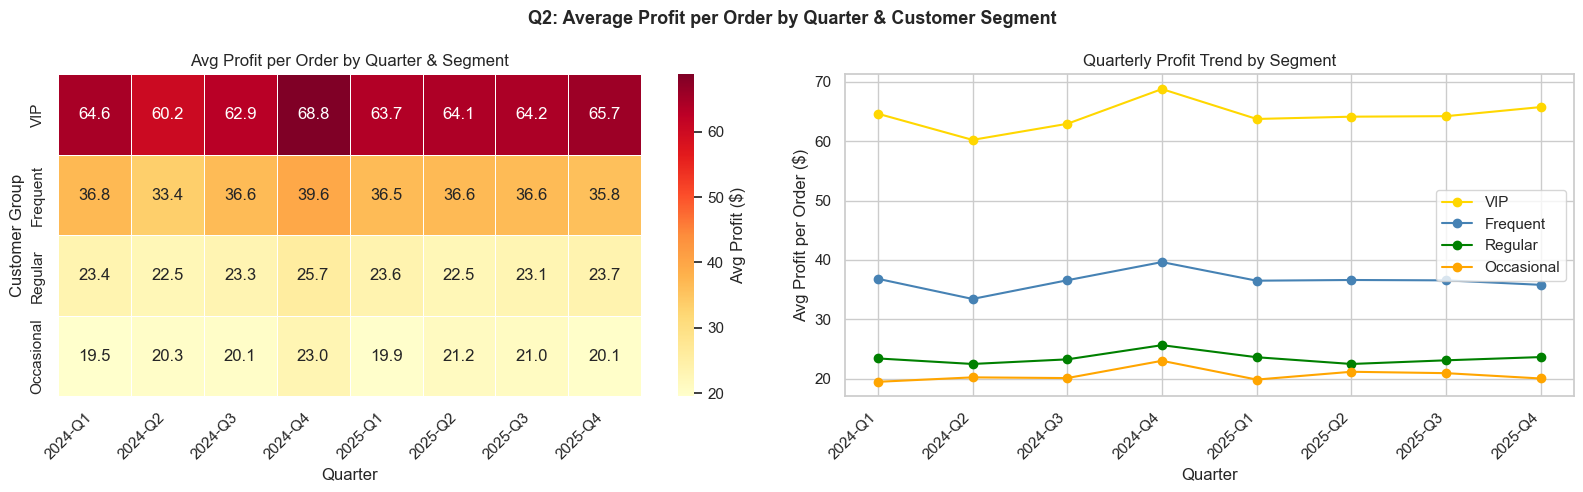

saved: q2_profit_by_quarter_segment.png


In [3]:
q2 = orders[
    orders['is_revenue_eligible'] &
    orders['customer_group'].notna() &
    orders['order_quarter'].notna()
].copy()

q2_agg = (
    q2.groupby(['order_quarter', 'customer_group'], as_index=False)
    .agg(
        avg_profit  = ('order_profit', 'mean'),
        order_count = ('order_id',     'count'),
    )
)

pivot = q2_agg.pivot(index='customer_group', columns='order_quarter', values='avg_profit')
seg_present = [s for s in SEGMENT_ORDER if s in pivot.index]
pivot = pivot.loc[seg_present]

print('Average profit per order ($):')
print(pivot.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Avg Profit ($)'})
ax.set_title('Avg Profit per Order by Quarter & Segment')
ax.set_xlabel('Quarter')
ax.set_ylabel('Customer Group')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

ax2 = axes[1]
quarters = sorted(q2_agg['order_quarter'].dropna().unique())
colors_map = {'VIP': 'gold', 'Frequent': 'steelblue', 'Regular': 'green',
              'Occasional': 'orange', 'Dormant': 'gray'}
for seg in seg_present:
    d = q2_agg[q2_agg['customer_group'] == seg].set_index('order_quarter')
    d = d.reindex(quarters)
    ax2.plot(quarters, d['avg_profit'],
             marker='o', label=seg, color=colors_map.get(seg))

ax2.set_xlabel('Quarter')
ax2.set_ylabel('Avg Profit per Order ($)')
ax2.set_title('Quarterly Profit Trend by Segment')
ax2.legend()
plt.setp(ax2.get_xticklabels(), rotation=45, ha='right')

plt.suptitle('Q2: Average Profit per Order by Quarter & Customer Segment',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'q2_profit_by_quarter_segment.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved: q2_profit_by_quarter_segment.png')

### Q2 Findings

**Finding:** VIP customers consistently generate the highest average profit per order
across all quarters. Occasional buyers show the lowest and most volatile returns.

**Note on Dormant:** Dormant does not appear in this table because Dormant buyers have
zero orders in the dataset -- not low activity, literally none. This affects ~23,700 of
the ~47,500 total buyers (~50%). See Q5 for acquisition/reactivation implications.


---
## Q3 — Referral Program Cost
*How much revenue is the referral program costing, and is it worth it?*

/Users/Parimala/Projects/Cap-one Data project real/Capital-one Data Project/src/features.py:197: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  del_orders["is_ref"] = del_orders["is_referred"].fillna(False).infer_objects(copy=False).astype(bool)


=== REFERRAL PROGRAM SUMMARY ===
 is_ref  total_orders  total_revenue  unique_buyers  avg_revenue_per_buyer  avg_orders_per_buyer
  False        201523    17119692.95          21437                 798.60                  9.40
   True         33714     2808604.49           3563                 788.27                  9.46

Estimated revenue lost to referral discounts: $24,368.40
(Rate: 10% off first order, referred buyers only )


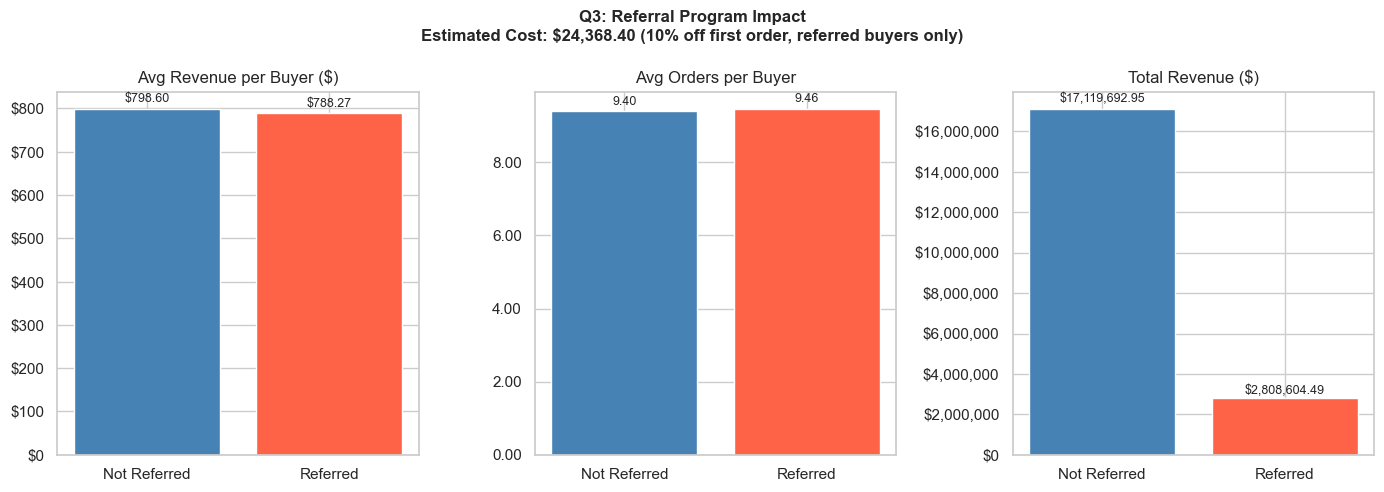

saved: q3_referral_program.png


In [4]:
from features import estimate_referral_cost

summary, discount_cost = estimate_referral_cost(orders)

print('=== REFERRAL PROGRAM SUMMARY ===')
print(summary.round(2).to_string(index=False))
print()
print(f'Estimated revenue lost to referral discounts: ${discount_cost:,.2f}')
print(f'(Rate: {REFERRAL_DISCOUNT_RATE:.0%} off first order, referred buyers only )')

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

metrics = [
    ('avg_revenue_per_buyer', 'Avg Revenue per Buyer ($)', axes[0]),
    ('avg_orders_per_buyer',  'Avg Orders per Buyer',      axes[1]),
    ('total_revenue',         'Total Revenue ($)',          axes[2]),
]

labels = ['Not Referred', 'Referred']
colors = ['steelblue', 'tomato']

for col, title, ax in metrics:
    vals = [
        summary.loc[summary['is_ref'] == False, col].values[0],
        summary.loc[summary['is_ref'] == True,  col].values[0],
    ]
    bars = ax.bar(labels, vals, color=colors)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'${x:,.0f}')
        if '$' in title else mticker.FuncFormatter(lambda x, _: f'{x:.2f}')
    )
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() * 1.01,
                f'${val:,.2f}' if '$' in title else f'{val:.2f}',
                ha='center', va='bottom', fontsize=9)

plt.suptitle(f'Q3: Referral Program Impact\n'
             f'Estimated Cost: ${discount_cost:,.2f} '
             f'({REFERRAL_DISCOUNT_RATE:.0%} off first order, referred buyers only)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'q3_referral_program.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved: q3_referral_program.png')

### Q3 Findings

**Finding:** Referred and non-referred buyers show nearly identical average revenue
per buyer and orders per buyer. The referral program is acquiring customers who behave
the same as organic customers -- the discount appears to provide no behavioral lift.


---
## Q4 — Black Friday Impact
*How does Black Friday affect volume and revenue by customer segment?*

Black Friday share of annual sales:
  year  total_orders  total_revenue  bf_orders  bf_revenue  bf_order_pct  bf_revenue_pct
2024.0        116082     9824768.40       1293   124588.07          1.11            1.27
2025.0        115862     9812674.18       1235    94296.43          1.07            0.96

Black Friday by segment:
customer_group  bf_orders  order_pct  bf_revenue  revenue_pct  avg_order_val
           VIP        327       0.88    53401.13         0.96         163.31
      Frequent        834       1.00    84004.71         1.12         100.73
       Regular        835       1.18    51511.64         1.24          61.69
    Occasional        420       1.29    22434.46         1.32          53.42


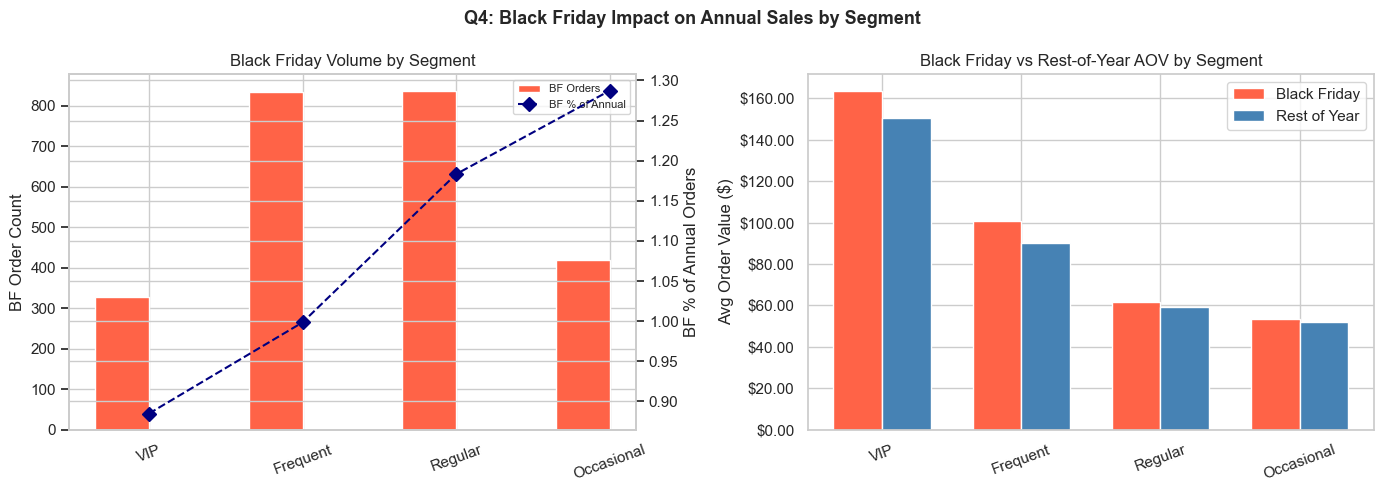

saved: q4_black_friday.png


In [5]:
delivered = orders[orders['is_revenue_eligible']].copy()
bf        = delivered[delivered['is_black_friday']]

annual = delivered.groupby(delivered['order_datetime'].dt.year).agg(
    total_orders  = ('order_id',      'count'),
    total_revenue = ('order_revenue', 'sum'),
).reset_index()
annual.columns = ['year', 'total_orders', 'total_revenue']

bf_annual = bf.groupby(bf['order_datetime'].dt.year).agg(
    bf_orders  = ('order_id',      'count'),
    bf_revenue = ('order_revenue', 'sum'),
).reset_index()
bf_annual.columns = ['year', 'bf_orders', 'bf_revenue']

summary_yr = annual.merge(bf_annual, on='year')
summary_yr['bf_order_pct']   = summary_yr['bf_orders']  / summary_yr['total_orders']  * 100
summary_yr['bf_revenue_pct'] = summary_yr['bf_revenue'] / summary_yr['total_revenue'] * 100

print('Black Friday share of annual sales:')
print(summary_yr.round(2).to_string(index=False))

bf_seg = bf[bf['customer_group'].notna()].groupby('customer_group').agg(
    bf_orders     = ('order_id',      'count'),
    bf_revenue    = ('order_revenue', 'sum'),
    avg_order_val = ('order_revenue', 'mean'),
).reset_index()

all_seg = delivered[delivered['customer_group'].notna()].groupby('customer_group').agg(
    all_orders  = ('order_id',      'count'),
    all_revenue = ('order_revenue', 'sum'),
).reset_index()

seg = bf_seg.merge(all_seg, on='customer_group')
seg['order_pct']   = seg['bf_orders']  / seg['all_orders']  * 100
seg['revenue_pct'] = seg['bf_revenue'] / seg['all_revenue'] * 100

_seg_order = [s for s in SEGMENT_ORDER if s in seg['customer_group'].values]
seg = seg.set_index('customer_group').reindex(_seg_order).reset_index()

print()
print('Black Friday by segment:')
print(seg[['customer_group','bf_orders','order_pct',
           'bf_revenue','revenue_pct','avg_order_val']].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
width = 0.35

ax = axes[0]
x  = range(len(seg))
ax.bar([i - width/2 for i in x], seg['bf_orders'], width,
       label='BF Orders', color='tomato')
ax2 = ax.twinx()
ax2.plot(list(x), seg['order_pct'], 'D--', color='navy',
         markersize=7, label='BF % of Annual')
ax.set_xticks(list(x))
ax.set_xticklabels(seg['customer_group'], rotation=20)
ax.set_ylabel('BF Order Count')
ax2.set_ylabel('BF % of Annual Orders')
ax.set_title('Black Friday Volume by Segment')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper right')

ax3 = axes[1]
non_bf     = delivered[delivered['customer_group'].notna() & ~delivered['is_black_friday']]
non_bf_aov = non_bf.groupby('customer_group')['order_revenue'].mean().reset_index()
non_bf_aov.columns = ['customer_group', 'non_bf_aov']
aov = seg[['customer_group', 'avg_order_val']].merge(non_bf_aov, on='customer_group')

_aov_order = [s for s in SEGMENT_ORDER if s in aov['customer_group'].values]
aov = aov.set_index('customer_group').reindex(_aov_order)

x3 = range(len(aov))
ax3.bar([i - width/2 for i in x3], aov['avg_order_val'], width,
        label='Black Friday', color='tomato')
ax3.bar([i + width/2 for i in x3], aov['non_bf_aov'], width,
        label='Rest of Year', color='steelblue')
ax3.set_xticks(list(x3))
ax3.set_xticklabels(aov.index, rotation=20)
ax3.set_ylabel('Avg Order Value ($)')
ax3.set_title('Black Friday vs Rest-of-Year AOV by Segment')
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}'))
ax3.legend()

plt.suptitle('Q4: Black Friday Impact on Annual Sales by Segment',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'q4_black_friday.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved: q4_black_friday.png')

### Q4 Findings

**Note on figures:** Revenue and profit for Black Friday orders already reflect the 20% discount
applied in the pipeline (`BLACK_FRIDAY_DISCOUNT_RATE = 0.20` in `features.py`). The raw price
data does not include this discount — it is computed before any aggregation.

**Finding:** Black Friday drives a volume spike concentrated in Regular and Occasional segments.
BF average order value is lower than rest-of-year by construction (20% reduction on product revenue),
making Black Friday primarily an acquisition and volume event rather than a margin event.
The shipping tier also shifts downward on BF (lower order totals → more orders hit the $7.99 tier),
which compresses net order profit further relative to rest-of-year orders.


---
## Q5 — Best Customer Base & Future KPIs
*Where is our best customer base and what KPIs should we track to acquire more customers?*

Revenue per buyer by region:
 region  unique_buyers  revenue_per_buyer  orders_per_buyer
Central           4724             791.29              9.44
   East           7184             802.46              9.33
  Other           2422             790.73              9.48
   West           9454             797.92              9.43


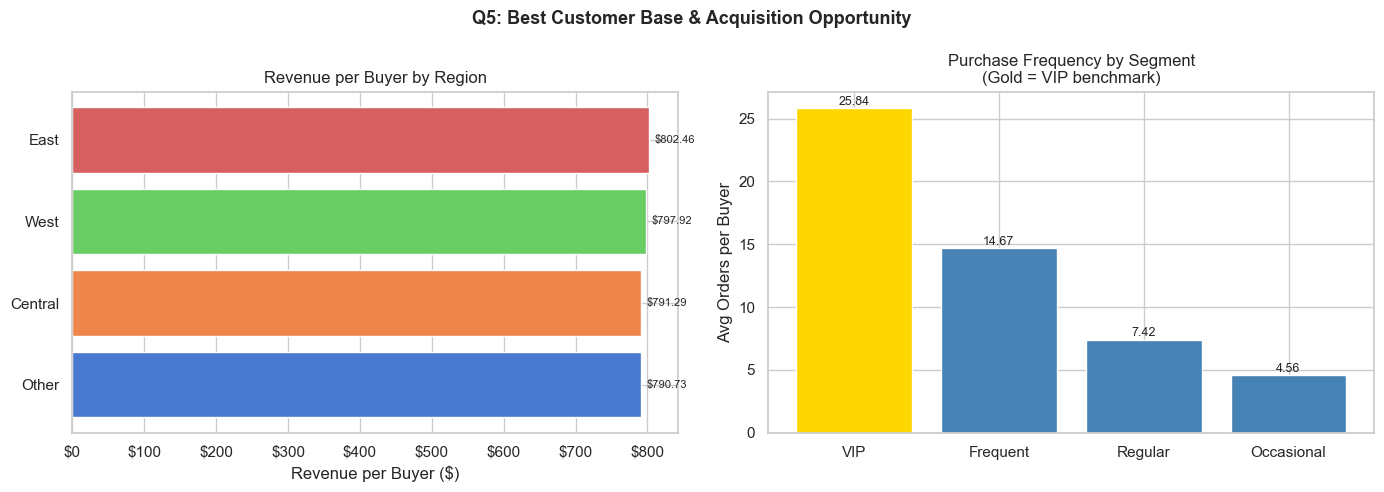

saved: q5_customer_base.png


In [6]:
delivered = orders[orders['is_revenue_eligible']].copy()

region_perf = (
    delivered[delivered['region'].notna()]
    .groupby('region')
    .agg(
        unique_buyers = ('buyer_id',      'nunique'),
        total_revenue = ('order_revenue', 'sum'),
        total_orders  = ('order_id',      'count'),
    )
    .reset_index()
)
region_perf['revenue_per_buyer'] = (
    region_perf['total_revenue'] / region_perf['unique_buyers']
)
region_perf['orders_per_buyer'] = (
    region_perf['total_orders'] / region_perf['unique_buyers']
)

print('Revenue per buyer by region:')
print(region_perf[['region','unique_buyers','revenue_per_buyer',
                   'orders_per_buyer']].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
rp = region_perf.sort_values('revenue_per_buyer')
bar_colors = sns.color_palette('muted', len(rp))
bars = ax.barh(rp['region'], rp['revenue_per_buyer'], color=bar_colors)
ax.set_xlabel('Revenue per Buyer ($)')
ax.set_title('Revenue per Buyer by Region')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
for bar in bars:
    w = bar.get_width()
    ax.text(w * 1.01, bar.get_y() + bar.get_height()/2,
            f'${w:,.2f}', va='center', fontsize=8)

ax2 = axes[1]
seg_freq = (
    delivered[delivered['customer_group'].notna()]
    .groupby('customer_group')
    .agg(
        orders = ('order_id', 'count'),
        buyers = ('buyer_id', 'nunique'),
    )
    .assign(opb=lambda d: d['orders'] / d['buyers'])
    .reindex([s for s in SEGMENT_ORDER if s in delivered['customer_group'].unique()])
    .reset_index()
)
colors2 = ['gold' if s == 'VIP' else 'steelblue' for s in seg_freq['customer_group']]
ax2.bar(seg_freq['customer_group'], seg_freq['opb'], color=colors2)
ax2.set_ylabel('Avg Orders per Buyer')
ax2.set_title('Purchase Frequency by Segment\n(Gold = VIP benchmark)')
for i, v in enumerate(seg_freq['opb']):
    ax2.text(i, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Q5: Best Customer Base & Acquisition Opportunity',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'q5_customer_base.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved: q5_customer_base.png')

### Q5 Findings

**Headline finding:** Roughly half the buyer base (~23,700 of ~47,500) has never placed
a single order. Before optimizing acquisition spend on new customers, it is worth
understanding why half of existing buyers never converted -- whether that is a
data/labeling artifact (e.g. "Dormant" assigned at signup rather than earned through
inactivity) or a genuine activation failure. Check signup_date distribution for Dormant
buyers: if they skew recent, the label is a default for new signups, not a business problem.

**Finding:** Revenue per buyer is broadly similar across regions -- the spread is narrow,
suggesting channel targeting matters more than geography alone.
VIP buyers order significantly more frequently than all other segments.

**Recommended KPIs to track:**

| KPI | Why |
|---|---|
| Buyer activation rate (% who place ≥1 order within N days) | This dataset offers zero visibility into it -- biggest gap |
| Revenue per new buyer (by region) | Measures acquisition quality, not just volume |
| 90-day repurchase rate | Leading indicator of whether new buyers become Frequent |
| BF new buyer conversion rate | Measures acquisition effectiveness of the event |
| Catalog profit margin % | Tracks health of product rationalization effort |
| Referred buyer 90-day retention | Measures referral program ROI beyond first order |

---
## Summary of Recommendations

| Question | Finding | Recommendation |
|---|---|---|
| Q1: 24/7 Staffing | Overnight = small % of orders | Tiered staffing -- full days, reduced overnight |
| Q2: Profit by Segment | VIP/Frequent drive stable profit | Invest in retention; Dormant = 0 orders, see Q5 |
| Q3: Referral Program | No behavioral lift vs organic | Confirm terms, run cohort retention analysis |
| Q4: Black Friday | Volume spike, margin compressed | Acquisition event + Q1 follow-up campaign |
| Q5: Best Customers | Similar revenue across regions | Focus on channel quality + VIP frequency KPIs |